In [ ]:
from collections import deque

class Value():
    def __init__(self, data, children=(), op=None):
        self.data = data
        self.children = children
        self.op = op
        self.label = ''
        self.grad = 0.0

    def __add__(self, other):
        value = Value(self.data + other.data, (self, other), '+')
        return value

    def __mul__(self, other):
        value = Value(self.data * other.data, (self, other), '*')
        return value

    def __repr__(self):
        return f"Value(data={self.data},children={len(self.children)},op={self.op})"

    def _backward_local(self):
        # push this node's gradient one step down to its children (chain rule)
        # += because a child can be reached through more than one path
        if self.op == '*':
            self.children[0].grad += self.children[1].data * self.grad
            self.children[1].grad += self.children[0].data * self.grad
        elif self.op == '+':
            self.children[0].grad += self.grad
            self.children[1].grad += self.grad

    def backward(self):
        # count how many edges lead into each node from above (its consumers),
        # i.e. how many gradient contributions it has to wait for
        pending = {}
        seen = {self}
        queue = deque([self])
        while queue:
            node = queue.popleft()
            for child in node.children:
                pending[child] = pending.get(child, 0) + 1
                if child not in seen:
                    seen.add(child)
                    queue.append(child)

        # zero every grad below the root so re-running backward doesn't accumulate
        for node in seen:
            if node is not self:
                node.grad = 0.0

        # BFS from the root, but only enqueue a node once all its consumers have
        # pushed their gradient into it (Kahn's algorithm), so its grad is final
        queue = deque([self])
        while queue:
            node = queue.popleft()
            node._backward_local()
            for child in node.children:
                pending[child] -= 1
                if pending[child] == 0:
                    queue.append(child)



a = Value(3.0); a.label='a'
b = Value(2.0); b.label='b'
c = a * b; c.label='c'
f = Value(3.0); f.label='f'
e = c * f; e.label='e'
g  = e + f; g.label='g'

g

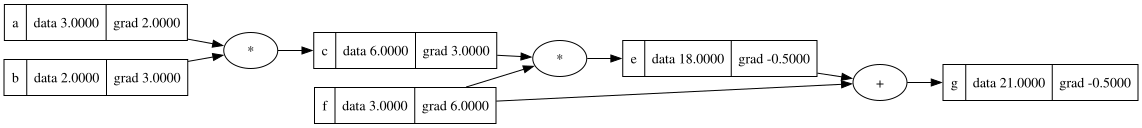

In [49]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v.children:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        label = getattr(n, 'label', '')
        grad = getattr(n, 'grad', None)
        text = f"{label} | data {n.data:.4f}" + (f" | grad {grad:.4f}" if grad is not None else "")
        dot.node(name=uid, label="{ " + text + " }", shape='record')
        if n.op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n.op, label=n.op)
            # and connect this node to it
            dot.edge(uid + n.op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + (n2.op or ''))

    return dot

g.grad = -0.5
g.backward()
draw_dot(g)